# Shape, HOG, and SIFT

Two photos of the Matterhorn taken from different spots differ in almost every global feature.
Yet some spots appear in both photos: the summit, the end of a rock band, the corner of a snow
field. This notebook follows the second half of the book section *Edges, Texture, and Shape*. It
starts with shape descriptors of segmented regions and shows why segmentation is the weak link
in natural photos. It then builds the histogram of oriented gradients (HOG) step by step and
finally finds, describes, and matches SIFT keypoints. At the end, SIFT searches the collection of
45 photos for the Matterhorn query.

**Learning goals:**
- Compute area, centroid, axis of least inertia, eccentricity, and circularity of a region
- See why segmenting a natural photo into objects is hard
- Build HOG step by step: gradients, cell histograms, block normalization, descriptor
- Test which changes HOG tolerates and which it does not
- Detect SIFT keypoints, read a 128-dimensional descriptor, and match keypoints with the ratio test
  and a geometric check
- See what SIFT can find in a collection and what it cannot

**Prerequisites:** demo ch10-02 (Sobel gradients, gradient histograms)

**Data:** the three photos of demo ch10-01 in `data/images/` and the collection of 45 photos from
the book: 43 photos from Wikimedia Commons are downloaded on the first run (about 16 MB, cached
in `data/.cache/images/ch10/`; `data/images/ch10_collection.json` lists authors and licenses).
SIFT comes with OpenCV (`opencv-python`); no neural network is needed.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
import cv2

from shared.display import print_table, display_md
from ch10_features import (PHOTOS, load_photos, lightness, gradients, load_collection, load_image,
                           sift_features, ratio_matches, consistent_matches, thumbnail, show_images)

photos = load_photos()
titles = {name: title for name, (_, title) in PHOTOS.items()}

## 1. Shape Descriptors

Shape features describe the outline or the area of a region, which must be found first. Once a
region is known as a binary mask, a few descriptors characterize it:

- **Area**: the share of the image covered by the region.
- **Centroid**: the mean $x$ and $y$ position of the region's pixels.
- **Axis of least inertia**: the line through the centroid around which the pixels have the
  smallest sum of squared distances. It is the direction of the largest spread of the pixel
  positions, the main eigenvector of their covariance matrix.
- **Eccentricity**: the ratio of the length to the width of the region, measured along the axis
  and perpendicular to it.
- **Circularity**: $4\pi A / P^2$ for a region with area $A$ and perimeter $P$; 1 for a circle and
  smaller for any other shape.

In [2]:
def shape_descriptors(mask):
    """Area share, centroid, axis of least inertia (degrees), eccentricity, and circularity of a binary mask."""
    ys, xs = np.nonzero(mask)
    cx, cy = xs.mean(), ys.mean()
    P = np.stack([xs - cx, ys - cy], 1)                     # pixel positions relative to the centroid
    eigval, eigvec = np.linalg.eigh(P.T @ P / len(P))       # covariance of the positions
    major, minor = eigvec[:, 1], eigvec[:, 0]               # largest spread first
    along, across = P @ major, P @ minor
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    perimeter = sum(cv2.arcLength(c, True) for c in contours)
    return dict(area=len(xs) / mask.size, centroid=(cx, cy),
                axis=np.degrees(np.arctan2(major[1], major[0])) % 180,
                eccentricity=np.ptp(along) / np.ptp(across),
                circularity=4 * np.pi * len(xs) / perimeter ** 2)

We test the descriptors on five simple regions. The fourth is the third, rotated by 30°.

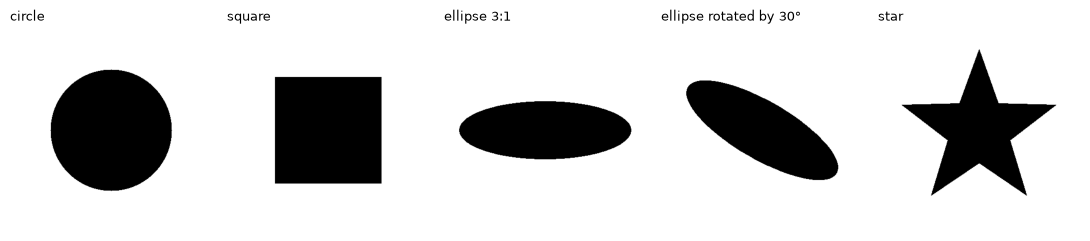

| Region                 |   Area | Centroid (x, y)   |   Axis (degrees) |   Eccentricity |   Circularity |
|:-----------------------|-------:|:------------------|-----------------:|---------------:|--------------:|
| circle                 |  28.3% | (200, 200)        |               90 |           1.00 |         0.902 |
| square                 |  27.8% | (200, 200)        |               90 |           1.00 |         0.793 |
| ellipse 3:1            |  19.2% | (200, 200)        |                0 |           2.98 |         0.611 |
| ellipse rotated by 30° |  19.2% | (200, 200)        |               30 |           2.96 |         0.603 |
| star                   |  19.5% | (199, 200)        |              147 |           1.04 |         0.271 |

In [3]:
def canvas():
    return np.zeros((400, 400), np.uint8)

def star(points=5, outer=160, inner=65):
    c = canvas()
    angles = np.radians(-90 + 180 / points * np.arange(2 * points))
    radii = np.where(np.arange(2 * points) % 2 == 0, outer, inner)
    cv2.fillPoly(c, [np.int32(np.stack([200 + radii * np.cos(angles), 200 + radii * np.sin(angles)], 1))], 1)
    return c

shapes = {"circle": cv2.circle(canvas(), (200, 200), 120, 1, -1),
          "square": cv2.rectangle(canvas(), (95, 95), (305, 305), 1, -1),
          "ellipse 3:1": cv2.ellipse(canvas(), (200, 200), (170, 57), 0, 0, 360, 1, -1),
          "ellipse rotated by 30°": cv2.ellipse(canvas(), (200, 200), (170, 57), 30, 0, 360, 1, -1),
          "star": star()}

show_images([np.repeat((1 - m)[..., None] * 255, 3, -1) for m in shapes.values()], list(shapes), height=2.2)
rows = []
for name, mask in shapes.items():
    d = shape_descriptors(mask)
    rows.append([name, d["area"], "({:.0f}, {:.0f})".format(*d["centroid"]), d["axis"], d["eccentricity"], d["circularity"]])
print_table(rows, headers=["Region", "Area", "Centroid (x, y)", "Axis (degrees)", "Eccentricity", "Circularity"],
            floatfmt=("", ".1%", "", ".0f", ".2f", ".3f"))

The rotated ellipse has the same area, eccentricity, and circularity as the upright one; only its
axis differs. Rotating every region to its axis therefore gives a standard orientation before
regions are compared. The circle and the square have no unique axis (any direction spreads
equally), so their axis value is arbitrary. The circle reaches a circularity of only about 0.9:
the perimeter of a pixel outline is longer than the smooth circle. The square comes close to its
exact value $\pi / 4 \approx 0.785$, and the star, with its long outline, is far from round.

### The weak link: finding the region

Shape descriptors work well when the object is easy to separate from the background, such as a
product on a white background. In natural photos, the segmentation step is the weak link. We try
the simplest method on the Matterhorn photo: Otsu's method picks the lightness threshold that best
separates bright from dark pixels, and connected bright pixels form a region.

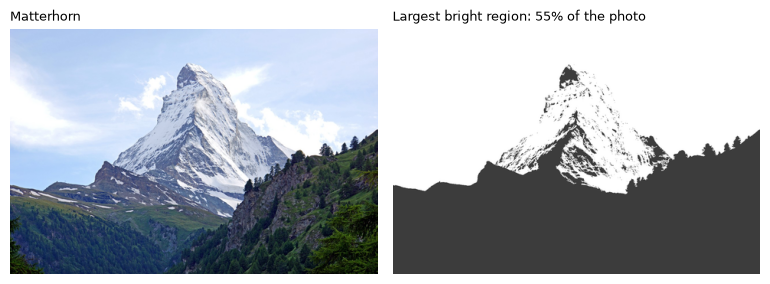

Otsu threshold: lightness **56.5**. The bright pixels form **957** separate regions; the largest covers 55% of the photo and has a circularity of 0.13.

In [4]:
L_m = lightness(photos["matterhorn"])
level, bright = cv2.threshold(np.uint8(np.clip(L_m * 2.55, 0, 255)), 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
n_regions, labels, stats, _ = cv2.connectedComponentsWithStats(bright, connectivity=8)
largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
region = labels == largest
d = shape_descriptors(region)

show_images([thumbnail(photos["matterhorn"]), thumbnail(np.uint8(np.where(region, 255, 60)[..., None].repeat(3, -1)))],
            ["Matterhorn", f"Largest bright region: {d['area']:.0%} of the photo"])
display_md(f"Otsu threshold: lightness **{level / 2.55:.1f}**. The bright pixels form **{n_regions - 1:,}** "
           f"separate regions; the largest covers {d['area']:.0%} of the photo and has a circularity of "
           f"{d['circularity']:.2f}.")

The largest bright region is not the mountain. It is the sky, the clouds, and the sunlit snow,
all in one piece, because they have the same lightness and touch each other. The Matterhorn has
no clean outline: its lower slopes merge with the neighboring ridges, and clouds cut through its
silhouette. The next two features describe shape without segmenting the image first.

## 2. Histograms of Oriented Gradients

The **histogram of oriented gradients** (HOG) describes local shape by the distribution of edge
directions in small cells. Dalal and Triggs made it popular in 2005 for detecting pedestrians, so
we use the photo of a person: a window of 64 by 128 pixels, the size of their detection window,
cut from the Federer photo.

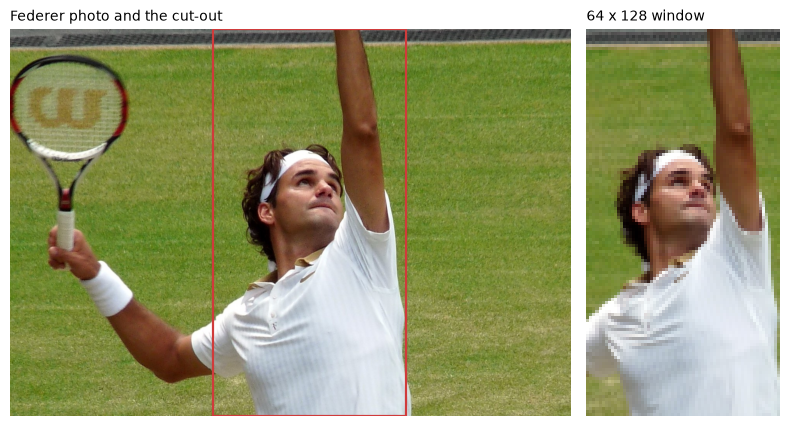

In [5]:
fed = photos["federer"]
crop = fed[:, 520:1016]                                           # 496 x 992 pixels, aspect ratio 1:2
window = cv2.resize(crop, (64, 128), interpolation=cv2.INTER_AREA)

fig, axes = plt.subplots(1, 2, figsize=(8, 4.6), gridspec_kw=dict(width_ratios=[1.45, 0.5]))
axes[0].imshow(fed)
axes[0].add_patch(Rectangle((520, 0), 496, 991, fill=False, ec="#d03b3b", lw=1.6))
axes[0].set_title("Federer photo and the cut-out", fontsize=10, loc="left")
axes[1].imshow(window, interpolation="nearest")
axes[1].set_title("64 x 128 window", fontsize=10, loc="left")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

HOG works in four steps.

**Step 1: gradients.** We compute $g_{\text{mag}}$ and $g_{\text{dir}}$ with the Sobel kernels of
demo ch10-02, without smoothing. HOG uses unsigned directions between 0° and 180°: a dark-to-bright
edge and a bright-to-dark edge with the same orientation count the same, because clothing can be
darker or brighter than the background.

**Step 2: cell histograms.** The window is divided into cells of 8 by 8 pixels. Each cell gets a
histogram with 9 direction bins of 20°, and each pixel votes for its direction with a weight equal
to its gradient magnitude. (Dalal and Triggs split each vote between the two nearest bins; we
give it to one bin.)

In [6]:
CELL, BINS = 8, 9

def hog_cells(L_img, cell=CELL, bins=BINS):
    """Cell histograms: for each cell of cell x cell pixels, the gradient magnitudes summed per direction bin."""
    gx, gy = gradients(L_img)
    mag = np.hypot(gx, gy)
    direction = np.degrees(np.arctan2(gy, gx)) % 180                  # unsigned: 0 to 180 degrees
    b = (direction // (180 / bins)).astype(int) % bins
    ny, nx = L_img.shape[0] // cell, L_img.shape[1] // cell
    yy, xx = np.mgrid[:ny * cell, :nx * cell]
    H = np.zeros((ny, nx, bins))
    np.add.at(H, (yy // cell, xx // cell, b[:ny * cell, :nx * cell]), mag[:ny * cell, :nx * cell])
    return H

L_w = lightness(window)
H_w = hog_cells(L_w)
display_md(f"The window has **{H_w.shape[1]} x {H_w.shape[0]} cells**, each with a histogram of {H_w.shape[2]} bins.")

The window has **8 x 16 cells**, each with a histogram of 9 bins.

We look at the cell with the strongest gradients: its 64 gradients and its histogram.

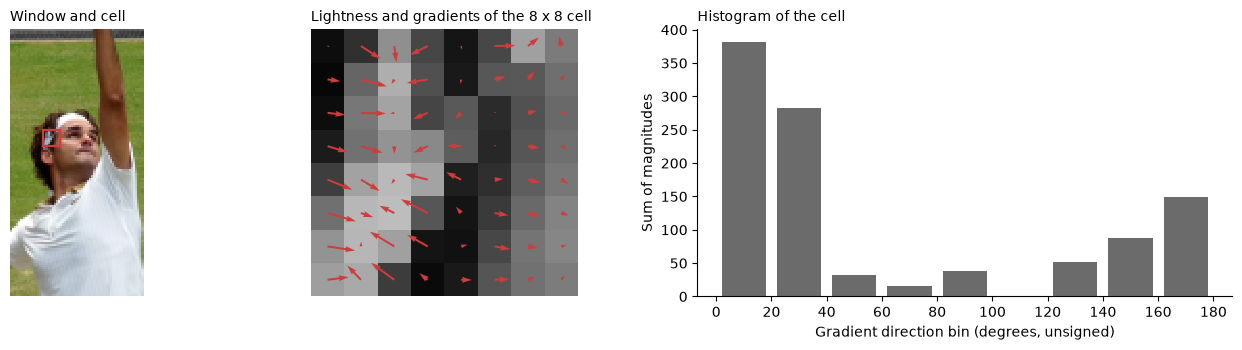

In [7]:
cy, cx = np.unravel_index(H_w.sum(2).argmax(), H_w.shape[:2])       # cell row and column
gx_w, gy_w = gradients(L_w)
sl = np.s_[cy * CELL:(cy + 1) * CELL, cx * CELL:(cx + 1) * CELL]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[0.6, 1, 1.4]))
axes[0].imshow(window, interpolation="nearest")
axes[0].add_patch(Rectangle((cx * CELL - 0.5, cy * CELL - 0.5), CELL, CELL, fill=False, ec="#d03b3b", lw=1.6))
axes[0].set_title("Window and cell", fontsize=10, loc="left")
axes[0].axis("off")
axes[1].imshow(L_w[sl], cmap="gray", vmin=0, vmax=100, interpolation="nearest")
yy, xx = np.mgrid[:CELL, :CELL]
axes[1].quiver(xx, yy, gx_w[sl], gy_w[sl], color="#d03b3b", angles="xy", scale_units="xy",
               scale=np.hypot(gx_w[sl], gy_w[sl]).max() / 0.9)
axes[1].set_title("Lightness and gradients of the 8 x 8 cell", fontsize=10, loc="left")
axes[1].axis("off")
axes[2].bar(np.arange(BINS) * 20 + 10, H_w[cy, cx], width=16, color="#6b6b6b")
axes[2].set_xticks(np.arange(0, 181, 20))
axes[2].set_xlabel("Gradient direction bin (degrees, unsigned)")
axes[2].set_ylabel("Sum of magnitudes")
axes[2].set_title("Histogram of the cell", fontsize=10, loc="left")
axes[2].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The strong gradients of the cell point across the edge it contains, so a few neighboring bins
collect most of the magnitude. The usual way to show all cells at once draws, in each cell, one line per bin
along the edge orientation (perpendicular to the gradient), as dark as the bin is large.

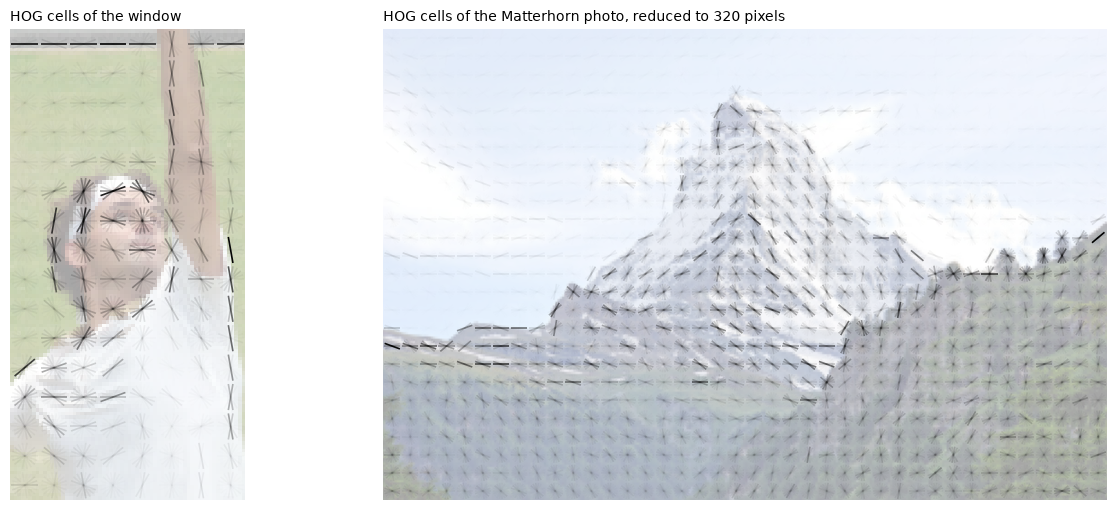

In [8]:
def draw_hog(ax, H, image=None):
    """Draw each cell's histogram as lines along the edge orientation, darker for larger bins."""
    ny, nx, bins = H.shape
    if image is not None:
        ax.imshow(image, extent=(0, nx, ny, 0), alpha=0.35)
    lines, weights = [], []
    for i in range(ny):
        for j in range(nx):
            for b in range(bins):
                edge = np.radians(b * 180 / bins + 90 / bins + 90)          # perpendicular to the gradient
                d = 0.45 * np.array([np.cos(edge), np.sin(edge)])
                lines.append([(j + 0.5 - d[0], i + 0.5 - d[1]), (j + 0.5 + d[0], i + 0.5 + d[1])])
                weights.append(H[i, j, b])
    w = np.array(weights) / max(weights)
    ax.add_collection(LineCollection(lines, colors=[(0, 0, 0, a) for a in w], linewidths=1.2))
    ax.set_xlim(0, nx), ax.set_ylim(ny, 0)
    ax.set_aspect("equal")
    ax.axis("off")

m_small = cv2.resize(photos["matterhorn"], (320, 213), interpolation=cv2.INTER_AREA)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw=dict(width_ratios=[0.5, 1.5]))
draw_hog(axes[0], H_w, window)
axes[0].set_title("HOG cells of the window", fontsize=10, loc="left")
draw_hog(axes[1], hog_cells(lightness(m_small)), m_small)
axes[1].set_title("HOG cells of the Matterhorn photo, reduced to 320 pixels", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

The cells trace the outline of the player: the raised arm, the head, the collar, and the shoulders. On the
Matterhorn, they trace the ridges. Flat areas such as the lawn and the sky contribute almost
nothing, because their gradients are weak.

**Step 3: block normalization.** Groups of 2 by 2 neighboring cells form a block of 16 by 16
pixels. The four histograms of a block are concatenated into 36 values and normalized to unit
length, which removes the effect of local lighting and contrast. The blocks overlap: they shift by
one cell at a time, so each cell appears in up to four blocks.

**Step 4: descriptor.** All block vectors are concatenated.

In [9]:
def hog_descriptor(H, eps=1e-6):
    """Overlapping 2 x 2 blocks of cells, each normalized to unit length, concatenated."""
    ny, nx, _ = H.shape
    blocks = []
    for i in range(ny - 1):
        for j in range(nx - 1):
            v = H[i:i + 2, j:j + 2].ravel()
            blocks.append(v / np.sqrt((v ** 2).sum() + eps ** 2))
    return np.concatenate(blocks)

d_w = hog_descriptor(H_w)
ny, nx, _ = H_w.shape
display_md(f"{nx - 1} x {ny - 1} = **{(nx - 1) * (ny - 1)} blocks** of 36 values: a descriptor of "
           f"**{len(d_w):,} values**, as in the book.")

7 x 15 = **105 blocks** of 36 values: a descriptor of **3,780 values**, as in the book.

### What HOG tolerates

The book says that HOG tolerates small shifts and changes of lighting, but not rotation or scale.
We edit the 496 by 992 cut-out, reduce each copy to the 64 by 128 window, and compare its HOG
descriptor with the original by cosine similarity. For contrast, we also compare a window cut
from the Matterhorn photo.

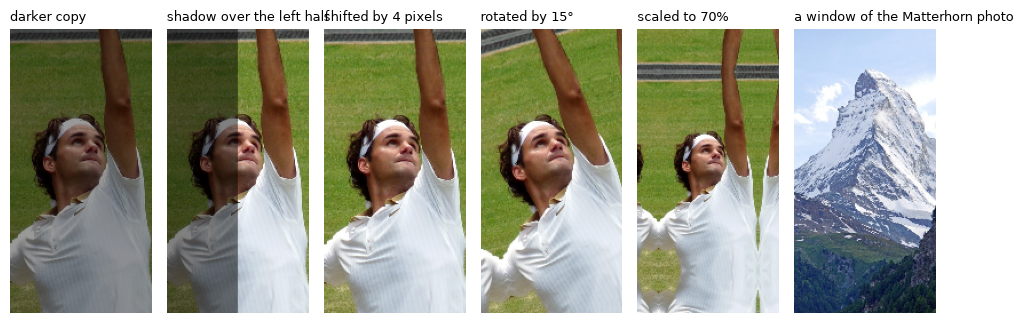

| Copy of the window                       |   Cosine similarity of the HOG descriptors |
|:-----------------------------------------|-------------------------------------------:|
| darker copy (every sRGB value times 0.6) |                                      0.995 |
| shadow over the left half                |                                      0.896 |
| shifted by 4 pixels                      |                                      0.958 |
| rotated by 15°                           |                                      0.548 |
| scaled to 70%                            |                                      0.485 |
| a window of the Matterhorn photo         |                                      0.456 |

In [10]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

def hog_of(img):
    return hog_descriptor(hog_cells(lightness(cv2.resize(img, (64, 128), interpolation=cv2.INTER_AREA))))

h, w = crop.shape[:2]
half_shadow = crop.astype(float)
half_shadow[:, :w // 2] *= 0.5
edits = {
    "darker copy (every sRGB value times 0.6)": np.round(crop * 0.6).astype(np.uint8),
    "shadow over the left half": np.round(half_shadow).astype(np.uint8),
    "shifted by 4 pixels": cv2.warpAffine(crop, np.float32([[1, 0, 4], [0, 1, 4]]), (w, h), borderMode=cv2.BORDER_REFLECT),
    "rotated by 15°": cv2.warpAffine(crop, cv2.getRotationMatrix2D((w / 2, h / 2), 15, 1), (w, h), borderMode=cv2.BORDER_REFLECT),
    "scaled to 70%": cv2.warpAffine(crop, cv2.getRotationMatrix2D((w / 2, h / 2), 0, 0.7), (w, h), borderMode=cv2.BORDER_REFLECT),
    "a window of the Matterhorn photo": photos["matterhorn"][:, 400:827],
}
show_images([cv2.resize(e, (124, 248)) for e in edits.values()], [n.split(" (")[0] for n in edits], height=3.2)
print_table([[name, cosine(d_w, hog_of(img))] for name, img in edits.items()],
            headers=["Copy of the window", "Cosine similarity of the HOG descriptors"], floatfmt=".3f")

The lighting changes and the shift leave the descriptor close to the original. A rotation of only
15° or a smaller person brings it down to about the level of an unrelated window: the edges now
fall into other cells and other direction bins. A detector built on HOG therefore searches the
image at several scales, and it finds upright persons only.

## 3. SIFT Keypoints

The **Scale-Invariant Feature Transform** (SIFT) first detects **keypoints**: small blob-like
structures, each at the scale at which it is most pronounced. A keypoint comes with a position, a
size, and a dominant gradient direction. SIFT then describes the neighborhood of each keypoint,
rotated to the dominant direction and scaled to the keypoint's size, by a 4 by 4 grid of
subregions with an 8-bin direction histogram each: $4 \cdot 4 \cdot 8 = 128$ values. OpenCV
provides the whole algorithm, which works on the gray version of the photo.

In [11]:
query = photos["matterhorn"]
kp_q, des_q = sift_features(query)
display_md(f"The Matterhorn photo has **{len(kp_q):,} SIFT keypoints**, each with a descriptor of "
           f"**{des_q.shape[1]} values**.")

The Matterhorn photo has **5,333 SIFT keypoints**, each with a descriptor of **128 values**.

We draw 150 randomly chosen keypoints in the region of the summit: each circle shows the size of a
keypoint, and the line its dominant direction.

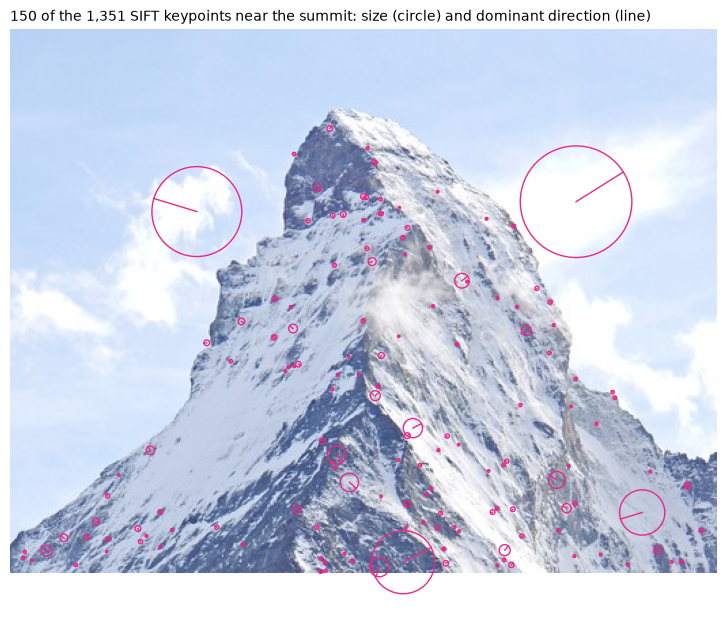

| Position (x, y)   |   Size (pixels) |   Direction (degrees) |   Response |
|:------------------|----------------:|----------------------:|-----------:|
| (292, 654)        |             1.9 |                   182 |      0.105 |
| (292, 654)        |             1.9 |                   337 |      0.105 |
| (287, 651)        |             2.2 |                   120 |      0.102 |
| (1113, 441)       |             1.8 |                     7 |      0.097 |
| (1164, 405)       |             9.8 |                   197 |      0.092 |

In [12]:
x0, y0, x1, y1 = 380, 60, 900, 460                                # region of the summit
strong = sorted(kp_q, key=lambda k: -k.response)                  # strongest first, for the table
in_region = [k for k in kp_q if x0 <= k.pt[0] < x1 and y0 <= k.pt[1] < y1]
shown = [in_region[i] for i in np.random.default_rng(0).choice(len(in_region), 150, replace=False)]

fig, ax = plt.subplots(figsize=(10, 7.7))
ax.imshow(query[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
for k in shown:
    r = k.size / 2
    a = np.radians(k.angle)
    ax.add_patch(plt.Circle(k.pt, r, fill=False, ec="#e7298a", lw=1))
    ax.plot([k.pt[0], k.pt[0] + r * np.cos(a)], [k.pt[1], k.pt[1] + r * np.sin(a)], color="#e7298a", lw=1)
ax.set_title(f"150 of the {len(in_region):,} SIFT keypoints near the summit: size (circle) and dominant direction (line)",
             fontsize=10, loc="left")
ax.axis("off")
plt.show()

print_table([[f"({k.pt[0]:.0f}, {k.pt[1]:.0f})", k.size, k.angle, k.response] for k in strong[:5]],
            headers=["Position (x, y)", "Size (pixels)", "Direction (degrees)", "Response"],
            floatfmt=("", ".1f", ".0f", ".3f"))

The keypoints sit on the corners of rock bands, on the ends of snow fields, and on small dark or
bright spots, at many sizes. They avoid the flat sky and the straight parts of edges, where a
position would be poorly defined. The table lists the five strongest keypoints of the whole photo:
small spots with a strong contrast. Its first two rows are the same spot with two directions:
when a second peak of the direction histogram reaches 80% of the highest, SIFT creates a second
keypoint at the same position.

The descriptor of the strongest keypoint consists of 16 histograms of 8 directions:

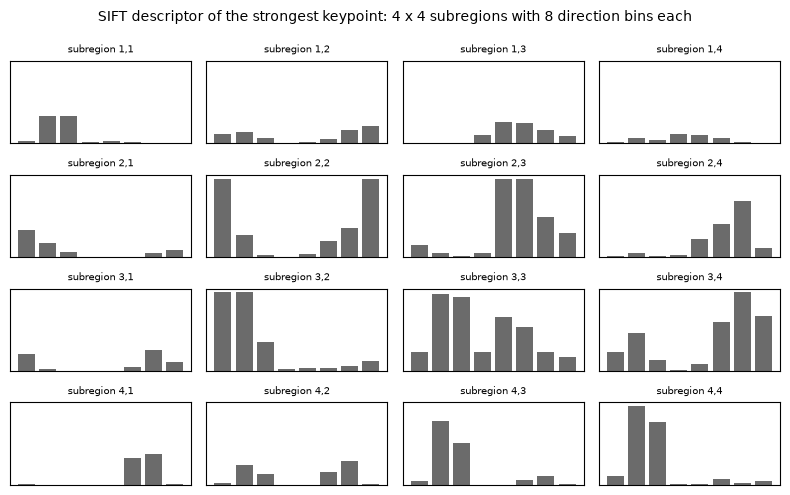

Length of the descriptor: **513**. OpenCV normalizes the descriptor to unit length, as the book describes, and stores it multiplied by 512.

In [13]:
desc = des_q[np.argmax([k.response for k in kp_q])]
fig, axes = plt.subplots(4, 4, figsize=(8, 5), sharey=True)
for s, ax in enumerate(axes.ravel()):
    ax.bar(range(8), desc[8 * s:8 * s + 8], color="#6b6b6b")
    ax.set_xticks([]), ax.set_yticks([])
    ax.set_title(f"subregion {s // 4 + 1},{s % 4 + 1}", fontsize=7)
plt.suptitle("SIFT descriptor of the strongest keypoint: 4 x 4 subregions with 8 direction bins each", fontsize=10)
plt.tight_layout()
plt.show()
display_md(f"Length of the descriptor: **{np.linalg.norm(desc):.0f}**. OpenCV normalizes the descriptor to "
           f"unit length, as the book describes, and stores it multiplied by 512.")

## 4. Matching Keypoints

To find the same object in two images, SIFT compares descriptors. For each descriptor of the
first image, we find its nearest and second-nearest descriptor in the second image by Euclidean
distance. The **ratio test** accepts a match only if the nearest neighbor is clearly closer:

$$\text{accept match } (\mathbf{d}, \mathbf{d}'_1) \quad \text{if} \quad \frac{\|\mathbf{d} - \mathbf{d}'_1\|}{\|\mathbf{d} - \mathbf{d}'_2\|} < 0.8$$

A final **geometric check** keeps only the matches that agree on one rotation, scaling, and
shift: RANSAC repeatedly picks two matches, computes the transformation they imply, and keeps the
transformation that most matches agree with (here: within 5 pixels). `ratio_matches` and
`consistent_matches` in `ch10_features.py` do these two steps with OpenCV.

We start with an easy case: a copy of the query, rotated by 30° and reduced to half its size.

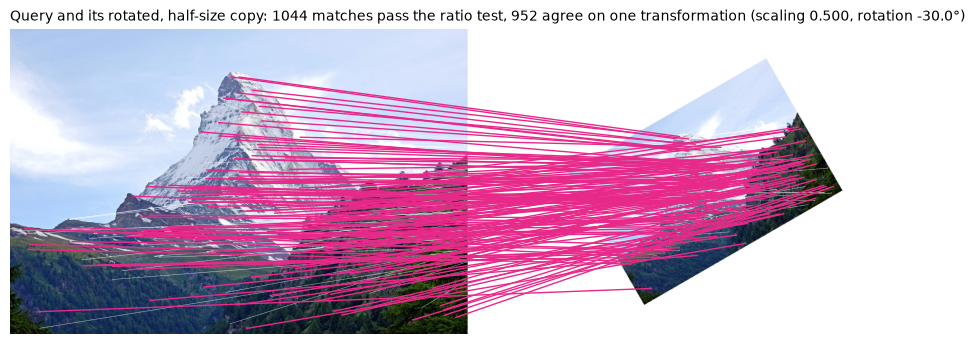

In [14]:
def draw_matches(img_a, kp_a, img_b, kp_b, matches, ok, title, height=420, max_lines=150):
    """Both images side by side; ratio-test matches in white, the consistent ones in pink
    (at most max_lines of each, chosen at random, so that the lines stay readable)."""
    sa, sb = height / img_a.shape[0], height / img_b.shape[0]
    a = cv2.resize(img_a, (round(img_a.shape[1] * sa), height))
    b = cv2.resize(img_b, (round(img_b.shape[1] * sb), height))
    gap = np.full((height, 12, 3), 255, np.uint8)
    off = a.shape[1] + gap.shape[1]
    fig, ax = plt.subplots(figsize=(12, 12 * height / (off + b.shape[1])))
    ax.imshow(np.concatenate([a, gap, b], 1))
    rng = np.random.default_rng(0)
    for good, color, lw in ((False, "white", 0.4), (True, "#e7298a", 1.0)):
        idx = np.flatnonzero(ok == good)
        for i in rng.permutation(idx)[:max_lines]:
                (xa, ya), (xb, yb) = kp_a[matches[i].queryIdx].pt, kp_b[matches[i].trainIdx].pt
                ax.plot([xa * sa, xb * sb + off], [ya * sa, yb * sb], color=color, lw=lw, alpha=1 if good else 0.6)
    ax.set_title(title, fontsize=10, loc="left")
    ax.axis("off")
    plt.show()

def transformation(M):
    """Scaling and rotation (degrees) of a 2 x 3 similarity transformation."""
    return np.hypot(M[0, 0], M[1, 0]), np.degrees(np.arctan2(M[1, 0], M[0, 0]))

h, w = query.shape[:2]
R = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 0.5)            # 30 degrees counterclockwise, half size
edited = cv2.warpAffine(query, R, (w, h), borderValue=(255, 255, 255))
kp_e, des_e = sift_features(edited)
m_e = ratio_matches(des_q, des_e)
M_e, ok_e = consistent_matches(kp_q, kp_e, m_e)
s, r = transformation(M_e)
draw_matches(query, kp_q, edited, kp_e, m_e, ok_e,
             f"Query and its rotated, half-size copy: {len(m_e)} matches pass the ratio test, {ok_e.sum()} agree on one "
             f"transformation (scaling {s:.3f}, rotation {r:.1f}°)")

SIFT finds the same spots although the copy is smaller and tilted, and the geometric check
recovers the edit: half the size and a rotation by 30°. (The plot draws only 150 of the
consistent matches.) (OpenCV counts the rotation in image
coordinates, where the $y$ axis points down, so a counterclockwise rotation appears with a minus
sign.)

### A second photo of the same mountain

The photo `matterhorn_zermatt` of the collection shows the east and north faces from Zermatt
as well, under a cloudless, deep blue sky. We follow the matches through the three stages.

| Stage                                         |   Matches |
|:----------------------------------------------|----------:|
| Query keypoints, each with a nearest neighbor |      5333 |
| Matches that pass the ratio test (0.8)        |       180 |
| Matches that agree on one transformation      |       100 |

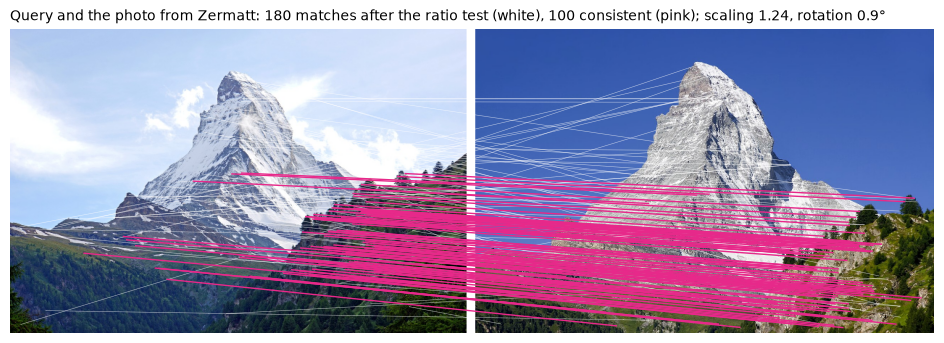

In [15]:
collection = load_collection()
by_id = {it["id"]: it for it in collection}

def load_rgb(item_id):
    return np.asarray(load_image(by_id[item_id]["path"]))

zermatt = load_rgb("matterhorn_zermatt")
kp_z, des_z = sift_features(zermatt)
m_z = ratio_matches(des_q, des_z)
M_z, ok_z = consistent_matches(kp_q, kp_z, m_z)
s, r = transformation(M_z)
print_table([["Query keypoints, each with a nearest neighbor", len(kp_q)],
             ["Matches that pass the ratio test (0.8)", len(m_z)],
             ["Matches that agree on one transformation", int(ok_z.sum())]],
            headers=["Stage", "Matches"])
draw_matches(query, kp_q, zermatt, kp_z, m_z, ok_z,
             f"Query and the photo from Zermatt: {len(m_z)} matches after the ratio test (white), "
             f"{ok_z.sum()} consistent (pink); scaling {s:.2f}, rotation {r:.1f}°")

The numbers match the book: 180 matches pass the ratio test, and 100 of them agree on one
transformation, in which the mountain appears about 1.24 times larger and rotated by about 1°.
The pink lines run in parallel and connect the rock bands and forested slopes below the summit.
The snow-covered summit contributes few of them, because its snow and light differ between the
two photos.

The threshold 0.8 is a trade-off. A lower threshold keeps fewer but safer matches, a higher one
more matches and more mistakes. We compare the Zermatt photo with an unrelated photo, Hong Kong at
night:

In [16]:
hong_kong = load_rgb("city_night_hong_kong")
kp_h, des_h = sift_features(hong_kong)
rows = []
for ratio in (0.6, 0.7, 0.8, 0.9, 1.0):
    row = [ratio if ratio < 1 else "no ratio test"]
    for kp_b, des_b in ((kp_z, des_z), (kp_h, des_h)):
        m = ratio_matches(des_q, des_b, ratio + 1e-9 if ratio == 1 else ratio)
        row += [len(m), int(consistent_matches(kp_q, kp_b, m)[1].sum())]
    rows.append(row)
print_table(rows, headers=["Ratio threshold", "Zermatt: matches", "Zermatt: consistent",
                           "Hong Kong: matches", "Hong Kong: consistent"])

| Ratio threshold   |   Zermatt: matches |   Zermatt: consistent |   Hong Kong: matches |   Hong Kong: consistent |
|:------------------|-------------------:|----------------------:|---------------------:|------------------------:|
| 0.6               |                 23 |                    22 |                    4 |                       3 |
| 0.7               |                 66 |                    56 |                    9 |                       4 |
| 0.8               |                180 |                   100 |                   61 |                      10 |
| 0.9               |                776 |                   160 |                  517 |                      29 |
| no ratio test     |               5333 |                   218 |                 5333 |                      11 |

At every threshold the same photo has many more consistent matches than the unrelated one. With
a stricter threshold, almost every accepted match is consistent; with a looser one, the ratio test
lets many more matches through, and the geometric check has to remove most of them.

### When the check is fooled

The book shows two more pairs. The photo `matterhorn_riffelberg` shows the same faces from
higher up; Hong Kong at night shares nothing with the query.

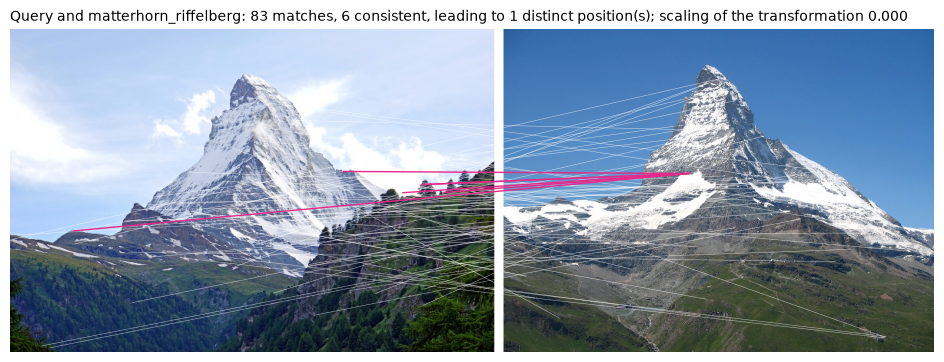

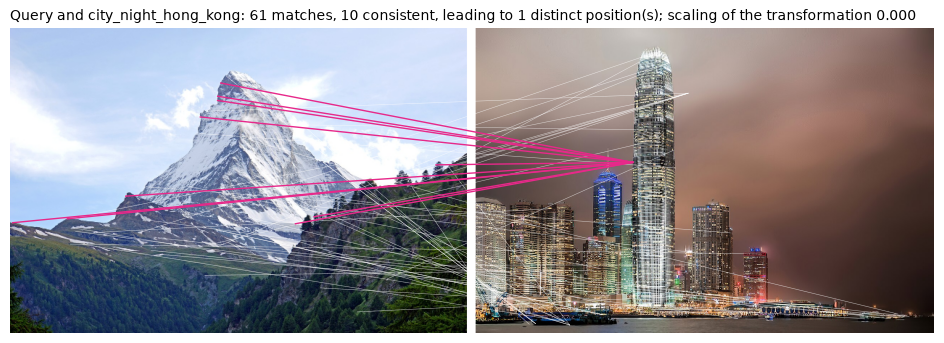

In [17]:
for item_id in ("matterhorn_riffelberg", "city_night_hong_kong"):
    img = load_rgb(item_id)
    kp_b, des_b = sift_features(img)
    m = ratio_matches(des_q, des_b)
    M, ok = consistent_matches(kp_q, kp_b, m)
    targets = {tuple(np.round(kp_b[m[i].trainIdx].pt)) for i in np.flatnonzero(ok)}    # distinct positions
    s, r = transformation(M)
    draw_matches(query, kp_q, img, kp_b, m, ok,
                 f"Query and {item_id}: {len(m)} matches, {ok.sum()} consistent, leading to {len(targets)} "
                 f"distinct position(s); scaling of the transformation {s:.3f}")

The Riffelberg photo still passes 83 matches through the ratio test, but they point in all
directions. Only 6 count as consistent, and they all lead to the same spot in the other photo:
the transformation that explains them shrinks the whole query onto that spot, with a scaling
close to 0. Hong Kong reaches 10 such matches in the same way. A practical system therefore also
rejects transformations with an implausible scaling. We accept scalings between 0.5 and 2.

In [18]:
def sift_consistent(a, b, plausible=(0.5, 2.0)):
    """Consistent matches between two (keypoints, descriptors) pairs; 0 if the scaling is implausible."""
    m = ratio_matches(a[1], b[1])
    M, ok = consistent_matches(a[0], b[0], m)
    if M is None or not plausible[0] <= transformation(M)[0] <= plausible[1]:
        return int(ok.sum()), 0
    return int(ok.sum()), int(ok.sum())

## Payoff: SIFT on the Whole Collection

We now compare the query with all 45 photos of the collection and rank them by the number of
consistent matches, once without and once with the check of the scaling.

In [19]:
q = (kp_q, des_q)
scores = np.array([sift_consistent(q, sift_features(np.asarray(load_image(it["path"])))) for it in collection])
ids = [it["id"] for it in collection]

rows = []
for col, label in ((0, "consistent matches"), (1, "with the scaling check")):
    order = np.argsort(-scores[:, col], kind="stable")
    rows.append([label] + [f"{ids[i]} ({scores[i, col]})" for i in order[:5]])
print_table(rows, headers=["Ranking by", "1", "2", "3", "4", "5"])

| Ranking by             | 1                        | 2                         | 3                        | 4                     | 5                    |
|:-----------------------|:-------------------------|:--------------------------|:-------------------------|:----------------------|:---------------------|
| consistent matches     | matterhorn_zermatt (100) | city_night_hong_kong (10) | tulips (10)              | rainier_meadow (8)    | desert_dunes (8)     |
| with the scaling check | matterhorn_zermatt (100) | macaw (6)                 | matterhorn_riffelsee (5) | matterhorn_winter (4) | eiger_north_face (4) |

In [20]:
others = [i for i, it in enumerate(collection) if it["is_matterhorn"] and it["id"] != "matterhorn_zermatt"]
non_mt = [i for i, it in enumerate(collection) if not it["is_mountain"]]
print_table([[ids[i], scores[i, 0], scores[i, 1]] for i in others]
            + [["highest value among the 25 photos without a mountain", scores[non_mt, 0].max(), scores[non_mt, 1].max()]],
            headers=["Other Matterhorn photo", "Consistent matches", "With the scaling check"])

| Other Matterhorn photo                               |   Consistent matches |   With the scaling check |
|:-----------------------------------------------------|---------------------:|-------------------------:|
| matterhorn_riffelberg                                |                    6 |                        0 |
| matterhorn_riffelsee                                 |                    5 |                        5 |
| matterhorn_winter                                    |                    4 |                        4 |
| matterhorn_autumn_trail                              |                    3 |                        0 |
| matterhorn_stellisee_sunset                          |                    5 |                        0 |
| matterhorn_riffelsee_sunrise                         |                    4 |                        0 |
| matterhorn_cervinia                                  |                    4 |                        0 |
| highest value among the 25 photos without a mountain |                   10 |                        6 |

The photo from nearly the same spot comes first, with 100 consistent matches. All other photos
have at most 10, so the rest of the ranking is noise: without the scaling check, a city at night
and a field of tulips follow; with the check, the values drop further, but the other seven photos
of the Matterhorn still score no higher than photos without any mountain.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">SIFT finds this scene, not this mountain</strong><br>
SIFT keypoints survive scaling, rotation, and a change of light, and the geometric check proves that two photos show the same scene: 100 consistent matches against at most 10. But SIFT matches the local patterns of one view. Taken from another position, in another season, or in other light, the Matterhorn is just another photo. Recognizing the mountain, or mountains in general, needs learned features (demo ch10-04).
</div>

## Summary

- Shape descriptors (area, centroid, axis, eccentricity, circularity) describe a region well,
  but natural photos rarely give clean regions: the sky, the snow, and the clouds of the
  Matterhorn photo form one bright region.
- HOG counts gradient directions in cells of 8 by 8 pixels and normalizes them in overlapping
  blocks: 3,780 values for a 64 by 128 window. It tolerates lighting changes and small shifts,
  but not rotation or scale.
- SIFT detects keypoints with a position, a size, and a direction, and describes each by 16
  histograms of 8 directions. The descriptors survive scaling and rotation.
- The ratio test removes ambiguous matches, and the geometric check keeps the matches that agree
  on one transformation. A plausible scaling is a third test.
- SIFT recognizes the same scene with strong evidence, but not the same mountain in other
  conditions, and not mountains in general.

## Try it yourself

1. **SIFT against HOG.** Compute the HOG descriptor of the rotated, half-size copy of the query
   and compare it with the HOG descriptor of the query (`hog_descriptor(hog_cells(lightness(...)))`
   on two images of the same size). SIFT matched the copy; what does HOG say?
2. **Stricter ratio test.** Rerun the payoff with a ratio threshold of 0.7 (add a `ratio`
   argument to `sift_consistent`). Does the gap between the Zermatt photo and the rest grow?
3. **Visual words.** Cluster the descriptors of a few photos with `sklearn.cluster.KMeans` into
   200 visual words, describe each photo by a histogram of its words, and rank the collection by
   the cosine similarity of these histograms. Which photos come first?